# Projetar a apuração antes do fim: o que funciona e o que engana

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amycardoso/projetor-apuracao/blob/main/notebooks/analise.ipynb)

Na noite da eleição, o TSE divulga o resultado aos poucos. As primeiras urnas não são uma amostra do Brasil, então o parcial engana. Este notebook mostra, com os dados do backtest, como um modelo de swing contra a eleição anterior corrige esse viés, quão cedo ele acerta e se as faixas de incerteza dele cumprem o que prometem.

Tudo aqui roda em poucos minutos e lê só arquivos versionados: os agregados do [replay](https://amycardoso.github.io/projetor-apuracao/) em `docs/data/` e os agregados pequenos em `notebooks/data/`, exportados por [`08_exportar_notebook.py`](08_exportar_notebook.py). Nenhum dado por seção. Os detalhes estão no [artigo](../reports/artigo.md).

**Colab (opcional).** A célula abaixo clona o repositório para ter os dados. Fora do Colab, ela não faz nada.

In [1]:
import os
import sys

if "google.colab" in sys.modules and not os.path.exists("notebooks/data"):
    !git clone -q --depth 1 https://github.com/amycardoso/projetor-apuracao.git
    %cd projetor-apuracao

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Polygon

RAIZ = Path.cwd() if (Path.cwd() / "docs" / "data").exists() else Path.cwd().parent
DADOS = RAIZ / "notebooks" / "data"


def replay(ano):
    return json.loads((RAIZ / "docs" / "data" / f"replay_{ano}.json").read_text(encoding="utf-8"))


# Paleta: tons categóricos em ordem fixa, tinta neutra para texto e eixos.
AZUL, LARANJA, AQUA, AMARELO, MAGENTA, VERDE, VIOLETA, VERMELHO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"
)
CINZA, TINTA, TINTA2 = "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e3",
    "grid.linewidth": 0.6, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False, "lines.linewidth": 2,
})
pd.options.display.float_format = "{:.2f}".format
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul", "Exterior"]
COR_REGIAO = dict(zip(REGIOES, [VERDE, VERMELHO, AMARELO, AZUL, VIOLETA, CINZA]))

## 1. O problema: as primeiras urnas não são o Brasil

As seções que chegam primeiro vêm de onde a apuração é mais rápida: o exterior, o Centro-Oeste, o Norte e o Sul no começo; o Sudeste e o Nordeste, que somam 70% dos votos, depois. Como o voto no PT varia muito por região, o parcial do PT começa longe do final e só converge perto do fim.

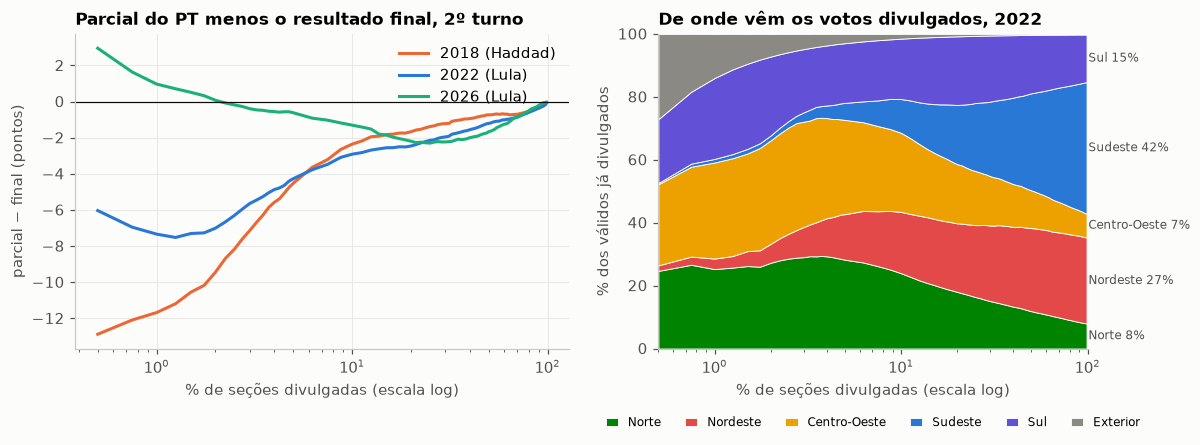

Composição dos válidos divulgados em 2022 (%):


,até 1% das seções,até 10%,final
Norte,25.30,23.90,7.90
Nordeste,3.30,19.50,27.40
Centro-Oeste,30.50,25.10,7.50
Sudeste,1.10,10.70,42.00
Sul,25.70,19.20,14.90
Exterior,14.00,1.50,0.30


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})

for ano, cor in [(2018, LARANJA), (2022, AZUL), (2026, AQUA)]:
    r = replay(ano)
    p = pd.DataFrame(r["pontos"])
    a.plot(p["secoes_pct"], p["apurado"] - r["final_pt"], color=cor, label=f"{ano} ({r['candidatos']['pt']})")
a.axhline(0, color=TINTA, linewidth=0.8)
a.set(xscale="log", xlabel="% de seções divulgadas (escala log)", ylabel="parcial − final (pontos)",
      title="Parcial do PT menos o resultado final, 2º turno")
a.legend(loc="upper right")

r22 = replay(2022)
p22 = pd.DataFrame(r22["pontos"])
comp = pd.DataFrame(list(p22["regioes"]))[REGIOES]
a2 = b
a2.stackplot(p22["secoes_pct"], comp.T.values, colors=[COR_REGIAO[r] for r in REGIOES], labels=REGIOES,
             edgecolor="#fcfcfb", linewidth=0.6)
final = pd.read_csv(DADOS / "composicao_final.csv").query("ano == 2022").set_index("regiao")["pct_validos"]
acum = 0
for reg in REGIOES:
    if final[reg] > 3:
        a2.text(101, acum + final[reg] / 2, f"{reg} {final[reg]:.0f}%", va="center", fontsize=8, color=TINTA2)
    acum += final[reg]
a2.set(xscale="log", xlim=(0.5, 100), ylim=(0, 100), xlabel="% de seções divulgadas (escala log)",
       ylabel="% dos válidos já divulgados", title="De onde vêm os votos divulgados, 2022")
a2.grid(False)
a2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=6, fontsize=8, handlelength=1)
fig.tight_layout()
plt.show()

print("Composição dos válidos divulgados em 2022 (%):")
display(pd.DataFrame({
    "até 1% das seções": comp.iloc[2].values,
    "até 10%": comp.iloc[p22.index[p22["secoes_pct"].round(2) == 10][0]].values,
    "final": final[REGIOES].values,
}, index=REGIOES).round(1))

Em 2022, com 1% das seções, Centro-Oeste, Norte e Sul eram 80% dos votos divulgados, contra 30% no final, e o Nordeste, onde Lula teve a maior vantagem, quase não aparecia. Por isso o parcial de Lula começou vários pontos abaixo do final. Em 2018 a ordem é simulada a partir da de 2022, porque o TSE não publica o horário de recebimento daquele ano.

## 2. O swing é mais estável que o voto, mas não é uniforme

A ideia do projetor: o voto de cada local muda pouco entre eleições, então o que já chegou diz quanto o PT ganhou ou perdeu (o *swing*) e esse swing se aplica ao que falta. Mas o swing de 2018 para 2022 varia muito por região. Um swing nacional único erraria; por isso os modelos estimam o swing por UF, por porte e por local.

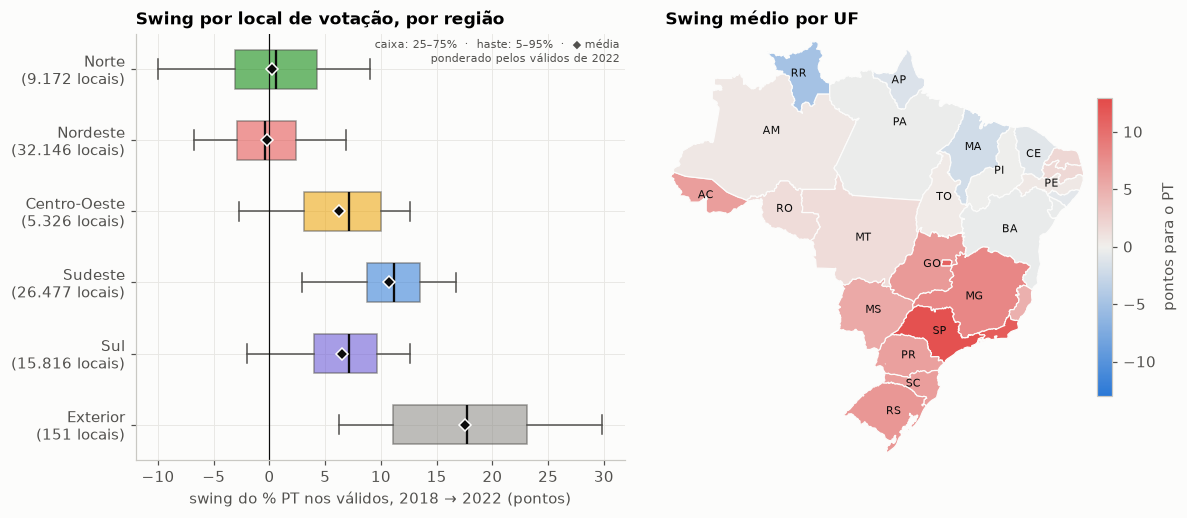

,swing médio (pontos)
uf,
RR,-4.91
MA,-2.06
AP,-1.39
DF,11.06
RJ,11.40
SP,12.33


In [4]:
sr = pd.read_csv(DADOS / "swing_regiao.csv").set_index("regiao").reindex(REGIOES)
su = pd.read_csv(DADOS / "swing_uf.csv").set_index("uf")
ufs = json.loads((DADOS / "ufs.geojson").read_text())

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
caixas = [{"label": f"{reg}\n({int(sr.loc[reg, 'locais']):,} locais)".replace(",", "."), "whislo": sr.loc[reg, "q5"],
           "q1": sr.loc[reg, "q25"], "med": sr.loc[reg, "q50"], "q3": sr.loc[reg, "q75"], "whishi": sr.loc[reg, "q95"],
           "mean": sr.loc[reg, "media"], "fliers": []} for reg in REGIOES]
bp = a.bxp(caixas, orientation="horizontal", showmeans=True, patch_artist=True, widths=0.55,
           meanprops={"marker": "D", "markerfacecolor": TINTA, "markeredgecolor": "#fcfcfb", "markersize": 6},
           medianprops={"color": TINTA, "linewidth": 1.5}, whiskerprops={"color": TINTA2}, capprops={"color": TINTA2})
for caixa, reg in zip(bp["boxes"], REGIOES):
    caixa.set(facecolor=COR_REGIAO[reg], alpha=0.55, edgecolor=TINTA2)
a.invert_yaxis()
a.axvline(0, color=TINTA, linewidth=0.8)
a.set(xlabel="swing do % PT nos válidos, 2018 → 2022 (pontos)",
      title="Swing por local de votação, por região")
a.text(0.99, 0.99, "caixa: 25–75%  ·  haste: 5–95%  ·  ◆ média\nponderado pelos válidos de 2022",
       transform=a.transAxes, ha="right", va="top", fontsize=7.5, color=TINTA2)

cmap = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", VERMELHO])
lim = np.ceil(su["swing_medio"].drop("ZZ").abs().max())
norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
for f in ufs["features"]:
    uf = f["properties"]["uf"]
    g = f["geometry"]
    poligonos = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    for pol in poligonos:
        b.add_patch(Polygon(pol[0], closed=True, facecolor=cmap(norm(su.loc[uf, "swing_medio"])),
                            edgecolor="#fcfcfb", linewidth=0.8))
    anel = np.array(max(poligonos, key=len)[0])
    if uf not in ("DF", "SE", "AL", "PB", "RN", "ES", "RJ"):
        b.text(*anel.mean(axis=0), uf, ha="center", va="center", fontsize=7, color=TINTA)
b.set(xlim=(-74.5, -34), ylim=(-34.5, 6), aspect="equal", title="Swing médio por UF")
b.axis("off")
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=b, shrink=0.7, pad=0.01)
cb.set_label("pontos para o PT", color=TINTA2)
fig.tight_layout()
plt.show()

display(su.drop("ZZ").sort_values("swing_medio")["swing_medio"].iloc[[0, 1, 2, -3, -2, -1]].rename("swing médio (pontos)").to_frame())

No Sudeste o PT ganhou em média 11 pontos de 2018 para 2022; no Nordeste ficou praticamente igual, porque já estava perto do teto. Mesmo dentro de uma região a dispersão é de vários pontos. É isso que o modelo precisa aprender com os primeiros locais que chegam, sem saber ainda como votou o resto.

## 3. A evolução dos modelos

Quatro projeções, em ordem de complexidade:

- **Apurado**: o parcial, sem correção;
- **Swing por UF**: o swing médio de cada UF aplicado às pendentes da mesma UF;
- **Camadas**: regressão do swing por local, com encolhimento de local para município, UF e porte, pesos escolhidos à mão (como no modelo de Rodrigo Mahlmeister);
- **Hierárquico-t**: o mesmo swing em camadas, mas com o *pooling* aprendido num modelo bayesiano com ruído Student-t.

O erro é o |projeção − final| do % do PT nos válidos, em 22 instantes de 0,5% a 95% das seções. "Tempo até cravar" é o primeiro % de seções a partir do qual o erro fica abaixo de 0,5 ponto até o fim. As noites de 2026 usam os modelos congelados com o que foi aprendido em 2018 e 2022.

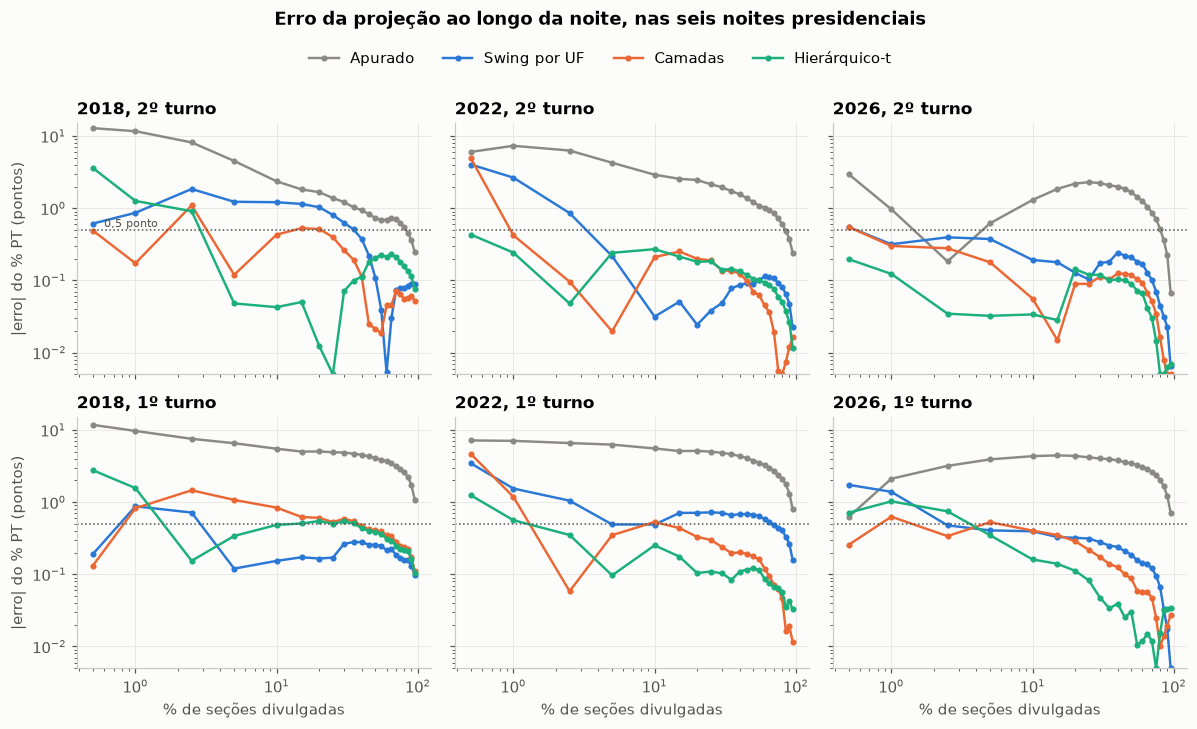

In [5]:
erros = pd.read_csv(DADOS / "erros.csv")
erros = erros[~erros["t"].round(4).isin([0.022, 0.0242])]  # instantes extras da comparação com Rodrigo
MODELOS = {"Apurado": "Apurado", "SwingUniformeUF": "Swing por UF",
           "SwingCamadasInterceptoPorte": "Camadas", "SwingHierarquico-t": "Hierárquico-t"}
COR_MODELO = dict(zip(MODELOS.values(), [CINZA, AZUL, LARANJA, AQUA]))
erros["modelo"] = erros["modelo"].map(MODELOS)
erros["noite"] = erros["ano"].astype(str) + ", " + erros["turno"].astype(str) + "º turno"
NOITES = [f"{a}, {t}º turno" for t in (2, 1) for a in (2018, 2022, 2026)]

fig, eixos = plt.subplots(2, 3, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, noite in zip(eixos.flat, NOITES):
    for nome, cor in COR_MODELO.items():
        g = erros[(erros["noite"] == noite) & (erros["modelo"] == nome)].sort_values("t")
        ax.plot(100 * g["t"], g["erro"].abs().clip(lower=0.005), color=cor, label=nome,
                marker="o", markersize=3, linewidth=1.6)
    ax.axhline(0.5, color=TINTA2, linestyle=":", linewidth=1)
    ax.set(title=noite, xscale="log", yscale="log", ylim=(0.005, 15))
for ax in eixos[1]:
    ax.set_xlabel("% de seções divulgadas")
for ax in eixos[:, 0]:
    ax.set_ylabel("|erro| do % PT (pontos)")
eixos[0, 0].text(0.6, 0.55, "0,5 ponto", fontsize=7.5, color=TINTA2)
handles, labels = eixos[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Erro da projeção ao longo da noite, nas seis noites presidenciais", y=1.06,
             fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

In [6]:
def tempo_ate_cravar(g, limite=0.5):
    g = g.sort_values("t")
    fora = (g["erro"].abs() >= limite).to_numpy()
    if fora[-1]:
        return np.nan
    i = np.flatnonzero(fora)
    return 100 * g["t"].iloc[i[-1] + 1 if len(i) else 0]


resumo = erros.groupby(["noite", "modelo"]).apply(
    lambda g: pd.Series({"erro médio": g["erro"].abs().mean(), "cravar (% seções)": tempo_ate_cravar(g)}),
    include_groups=False,
).unstack("modelo").swaplevel(axis=1)[list(MODELOS.values())].reindex(NOITES)
resumo.loc["média das 6 noites"] = resumo.mean()
resumo.loc["média das 6 noites", [c for c in resumo.columns if c[1] != "erro médio"]] = np.nan


def destacar(linha):
    estilo = pd.Series("", index=linha.index)
    for medida in ("erro médio", "cravar (% seções)"):
        cols = [c for c in linha.index if c[1] == medida]
        if linha[cols].notna().any():
            estilo[linha[cols].astype(float).idxmin()] = "font-weight: bold"
    return estilo


resumo.style.apply(destacar, axis=1).format("{:.2f}", subset=[c for c in resumo.columns if c[1] == "erro médio"]) \
    .format("{:g}", subset=[c for c in resumo.columns if c[1] != "erro médio"], na_rep="—")

Corrigir pelo swing por UF já tira a maior parte do erro do apurado. Os modelos por local cravam mais cedo: o hierárquico fica abaixo de 0,5 ponto com até 5% das seções em cinco das seis noites, e a exceção é 2018, 1º turno (40%). O hierárquico tem o menor erro médio em quatro das seis noites, inclusive nas duas de 2026, que ele não tinha visto; o modelo em camadas ganha em 2018, 2º turno, e o swing por UF, em 2018, 1º turno, uma noite em que os modelos por local erram nos primeiros instantes.

## 4. As faixas: o que o modelo promete e o que entrega

Uma faixa de 90% deveria conter o resultado final em 90% dos instantes. O gráfico compara o nível prometido (nominal) com a fração de instantes em que o final de fato caiu dentro dela (empírica). Três faixas:

- **só do modelo**: os quantis da posterior do hierárquico, como saem do PyMC;
- **recalibrada**: a mesma posterior, com o desvio multiplicado por um fator conformal ajustado em outras noites;
- **com erro comum**: a posterior somada a um erro compartilhado por todas as seções pendentes, que cresce quando o histórico explica pouco do swing já divulgado. A escala desse erro é calibrada em outras noites.

As noites de 2018 e 2022 deixam a data inteira de fora da calibração. As de 2026 usam a calibração congelada.

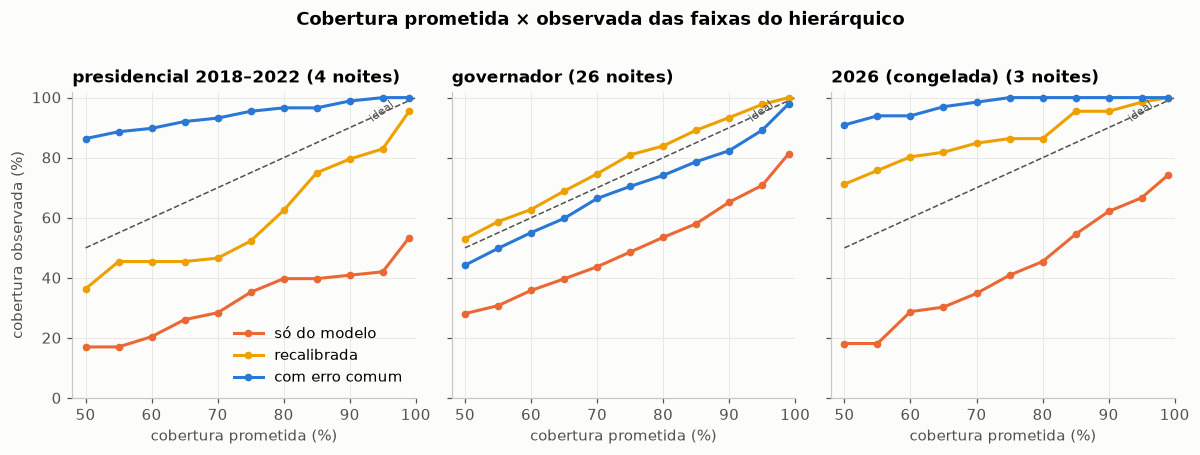

Faixa de 90%: cobertura observada (largura média em pontos)


grupo,presidencial 2018–2022,governador,2026 (congelada)
só do modelo,"41% (0,6)","65% (2,6)","62% (0,3)"
recalibrada,"80% (1,5)","93% (6,3)","95% (0,8)"
com erro comum,"99% (2,2)","82% (3,4)","100% (1,3)"


In [7]:
cob = pd.read_csv(DADOS / "cobertura.csv")
METODOS = {"posterior": ("só do modelo", LARANJA), "recalibrada": ("recalibrada", AMARELO), "erro comum": ("com erro comum", AZUL)}
GRUPOS = ["presidencial 2018–2022", "governador", "2026 (congelada)"]
media = cob.groupby(["grupo", "metodo", "nivel"])[["cobertura", "largura"]].mean().reset_index()
n_noites = cob.groupby("grupo")["noite"].nunique()

fig, eixos = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for ax, grupo in zip(eixos, GRUPOS):
    ax.plot([50, 100], [50, 100], color=TINTA2, linestyle="--", linewidth=1)
    for m, (nome, cor) in METODOS.items():
        g = media[(media["grupo"] == grupo) & (media["metodo"] == m)]
        ax.plot(100 * g["nivel"], 100 * g["cobertura"], color=cor, marker="o", markersize=4, label=nome)
    ax.set(title=f"{grupo} ({n_noites[grupo]} noites)", xlim=(48, 100), ylim=(0, 102), xlabel="cobertura prometida (%)")
    ax.text(97, 92, "ideal", rotation=36, fontsize=7.5, color=TINTA2, ha="right")
eixos[0].set_ylabel("cobertura observada (%)")
eixos[0].legend(loc="lower right")
fig.suptitle("Cobertura prometida × observada das faixas do hierárquico", fontweight="bold", fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

t90 = media[media["nivel"] == 0.9].assign(
    celula=lambda d: (100 * d["cobertura"]).round().astype(int).astype(str) + "% (" + d["largura"].round(1).astype(str).str.replace(".", ",") + ")"
).pivot(index="metodo", columns="grupo", values="celula").reindex(list(METODOS))[GRUPOS]
t90.index = [METODOS[m][0] for m in t90.index]
print("Faixa de 90%: cobertura observada (largura média em pontos)")
display(t90)

In [8]:
pior = cob[(cob["nivel"] == 0.9) & (cob["grupo"] != "governador")].pivot(index="noite", columns="metodo", values="cobertura")
pior = (100 * pior[list(METODOS)]).round().astype(int)
pior.columns = [METODOS[m][0] for m in pior.columns]
print("Faixa de 90%, por noite presidencial: % dos instantes em que o final ficou dentro")
display(pior)

Faixa de 90%, por noite presidencial: % dos instantes em que o final ficou dentro


,só do modelo,recalibrada,com erro comum
noite,,,
2018 1T PT,9,27,100
2018 2T PT,45,91,95
2022 1T PT,91,100,100
2022 2T PT,18,100,100
2026 1T PT,64,91,100
2026 1T adversário,77,95,100
2026 2T PT,45,100,100


A faixa só do modelo fica muito abaixo da diagonal: promete 90% e cobre cerca de 40% nas noites presidenciais. O motivo é que ela trata cada seção pendente como um sorteio independente, então a incerteza encolhe rápido à medida que os votos chegam. Na prática, o que falta erra junto: se o modelo subestima o swing do Nordeste, subestima em todas as seções do Nordeste ainda não divulgadas. A recalibração ajuda na média, mas um fator fixo não resolve noites como 2018, 1º turno. O erro comum modela exatamente esse erro compartilhado e é a única faixa que não falha em nenhuma noite presidencial. O custo é largura nas noites fáceis: em 2026 ela cobriu 100% com cerca de 1,3 ponto de largura. Nas noites de governador, a recalibrada cobre mais (93% contra 82%), mas com faixas quase duas vezes mais largas.

## 5. 2026: o teste fora da amostra

Em 25/10/2026, os modelos e a calibração estavam congelados com o que foi aprendido em 2018 e 2022. A divulgação do TSE foi suspensa às 17h07, com cerca de 0,25% das urnas, quando a votação foi prorrogada até as 19h, e retomada às 19h03. Entre 19h44 e 20h23, o parcial mostrou Flávio Bolsonaro na frente.

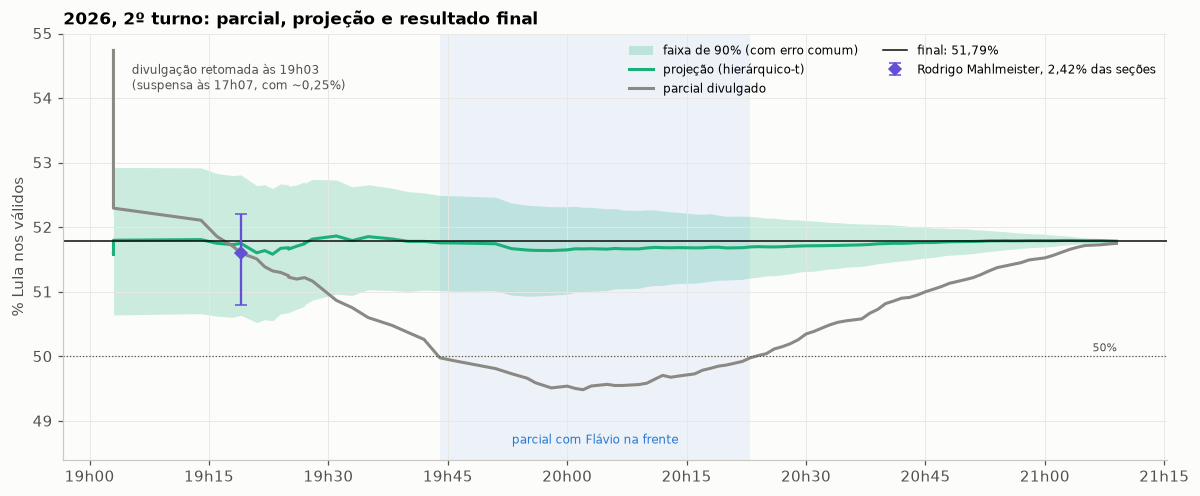

Projeção do hierárquico a partir de 1% das seções: 51.58% a 51.87%
Menor limite inferior da faixa de 90%: 50.32%   ·   final: 51.79%


In [9]:
r26 = replay(2026)
p = pd.DataFrame(r26["pontos"])
p["hora"] = pd.to_datetime("2026-10-25 " + p["horario"])
f90 = np.array(list(p["faixa90"]))
final = r26["final_pt"]
FINAL = f"{final + 1e-9:.2f}"  # 51,785 arredonda para 51,79

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(p["hora"], f90[:, 0], f90[:, 1], color=AQUA, alpha=0.22, linewidth=0, label="faixa de 90% (com erro comum)")
ax.plot(p["hora"], p["hierarquico"], color=AQUA, label="projeção (hierárquico-t)")
ax.plot(p["hora"], p["apurado"], color=CINZA, label="parcial divulgado")
ax.axhline(final, color=TINTA, linewidth=1, label=f"final: {FINAL}%".replace(".", ","))
ax.axhline(50, color=TINTA2, linewidth=0.8, linestyle=":")
ax.text(p["hora"].iloc[-1], 50.08, "50%", fontsize=7.5, color=TINTA2, ha="right")

frente = p[p["apurado"] < 50]
ax.axvspan(frente["hora"].min(), frente["hora"].max(), color=AZUL, alpha=0.07, linewidth=0)
ax.text(frente["hora"].min() + (frente["hora"].max() - frente["hora"].min()) / 2, 48.65,
        "parcial com Flávio na frente", ha="center", fontsize=8, color=AZUL)

# Rodrigo Mahlmeister: projeção pública com 2,42% das seções (≈ 19h19 na curva reconstruída).
hora_rod = p["hora"].iloc[(p["secoes_pct"] - 2.42).abs().idxmin()]
ax.errorbar(hora_rod, 51.6, yerr=[[51.6 - 50.8], [52.2 - 51.6]], fmt="D", color=VIOLETA, markersize=6,
            capsize=4, linewidth=1.5, label="Rodrigo Mahlmeister, 2,42% das seções")

ax.annotate("divulgação retomada às 19h03\n(suspensa às 17h07, com ~0,25%)", xy=(p["hora"].iloc[0], p["apurado"].iloc[0]),
            xytext=(12, -8), textcoords="offset points", fontsize=8, color=TINTA2, va="top")
ax.set(ylim=(48.4, 55), ylabel="% Lula nos válidos", title="2026, 2º turno: parcial, projeção e resultado final")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Hh%M"))
ax.legend(loc="upper right", ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

depois = p[p["secoes_pct"] >= 1]
print(f"Projeção do hierárquico a partir de 1% das seções: {depois['hierarquico'].min():.2f}% a {depois['hierarquico'].max():.2f}%")
print(f"Menor limite inferior da faixa de 90%: {f90[:, 0].min():.2f}%   ·   final: {FINAL}%")

O parcial foi de 54,7% a 49,5% e voltou; a projeção ficou entre 51,6% e 51,9% a noite inteira, e a faixa de 90% nunca deixou de apontar vitória de Lula. A comparação com Rodrigo Mahlmeister ([@ro_mahl](https://x.com/ro_mahl)), que publicou projeções do mesmo tipo durante a noite, usa os números públicos dele no mesmo % de seções. O código dele é privado e não foi usado.

In [10]:
erros26 = pd.read_csv(DADOS / "erros.csv").query("ano == 2026 and modelo == 'SwingHierarquico-t'")
proj_2t = erros26[(erros26["turno"] == 2) & np.isclose(erros26["t"], 0.0242)]["projecao"].iloc[0]
proj_1t = erros26[(erros26["turno"] == 1) & np.isclose(erros26["t"], 0.022)]["projecao"].iloc[0]

# Números públicos de Rodrigo; faixas de 95% deste projeto como em reports/07_eleicao_2026.md.
comparacao = pd.DataFrame([
    {"instante": "2026 1T, 2,2% das seções", "candidato": "Flávio Bolsonaro", "Rodrigo": "47,01", "este projeto (95%)": "46,51 (45,1–47,9)", "final": "47,03"},
    {"instante": "2026 1T, 2,2% das seções", "candidato": "Lula", "Rodrigo": "45,50", "este projeto (95%)": f"{proj_1t:.2f} (44,3–47,5)", "final": "45,16"},
    {"instante": "2026 2T, 2,42% das seções", "candidato": "Lula", "Rodrigo": "51,6 (50,8–52,2)", "este projeto (95%)": f"{proj_2t:.2f} (50,4–53,1)", "final": FINAL},
]).set_index(["instante", "candidato"])
comparacao.apply(lambda c: c.str.replace(".", ",", regex=False))

Rodrigo  \
instante                  candidato                            
2026 1T, 2,2% das seções  Flávio Bolsonaro             47,01   
                          Lula                         45,50   
2026 2T, 2,42% das seções Lula              51,6 (50,8–52,2)   

                                           este projeto (95%)  final  
instante                  candidato                                   
2026 1T, 2,2% das seções  Flávio Bolsonaro  46,51 (45,1–47,9)  47,03  
                          Lula              45,90 (44,3–47,5)  45,16  
2026 2T, 2,42% das seções Lula              51,71 (50,4–53,1)  51,79

No 2º turno, as duas projeções ficaram a menos de 0,2 ponto do final. No 1º turno, o modelo de Rodrigo acertou melhor naquele instante, sobretudo em Flávio; o ponto de partida dele usava uma pesquisa eleitoral, e este projeto não usa nenhuma. A faixa daqui é mais larga que a dele: é o preço de cobrir as noites difíceis de 2018 e 2022.

## 6. Conclusões e limitações

**Conclusões**

- O parcial engana porque a ordem de chegada tem viés regional, e o voto no PT varia muito por região. Corrigir pelo swing contra a eleição anterior tira a maior parte do erro.
- Modelar o swing por local, com *pooling* entre local, município, UF e porte, crava o resultado (erro abaixo de 0,5 ponto até o fim) com até 5% das seções em cinco das seis noites. Aprender o pooling num hierárquico bayesiano ganha do pooling escolhido à mão em quatro das seis noites.
- As faixas que saem só do modelo são estreitas demais: prometem 90% e cobrem perto de 40%. Um erro comum às seções pendentes, calibrado em outras noites, corrige isso sem olhar a noite avaliada.
- Em 2026, com tudo congelado, a projeção ficou a menos de 0,2 ponto do final desde as primeiras urnas, e a faixa de 90% nunca incluiu derrota de Lula.

**Limitações**

- São poucas noites: seis presidenciais e 26 de governador, e os instantes de uma noite são muito correlacionados. Cada cobertura é uma estimativa ruidosa.
- A ordem de chegada de 2018 é simulada a partir da de 2022, porque não há horário de recebimento publicado para aquele ano.
- O backtest usa os boletins de urna finais, reordenados pelo horário de recebimento. Na noite real, há atrasos, retotalizações e a pausa de 2026, que não mudam o % de seções usado como relógio.
- O modelo depende de pareamento de locais entre eleições; seções novas ou rezoneadas caem para níveis mais agregados.
- Só há dois candidatos competitivos no recorte (PT contra o principal adversário). Um 1º turno fragmentado ou uma eleição sem par na anterior exigiriam outra formulação.
- A comparação com Rodrigo usa poucos instantes publicados, então não permite dizer qual modelo é melhor em geral.